# Experimentos reproducibles con estrategias de ruleta

## Objetivo

Ejecutar múltiples partidas en condiciones comparables y analizar
los resultados de cada estrategia.

## Preguntas del experimento

- ¿Qué proporción de partidas termina con ganancias?
- ¿Cuál es el beneficio o la pérdida media por partida?
- ¿Cuánto varían los resultados entre partidas?
- ¿Con qué frecuencia el saldo resulta insuficiente para realizar
  la siguiente apuesta?

## Organización de los datos

Mantendremos dos tablas:

- Tiradas: una fila por tirada, identificando a qué partida pertenece.
- Partidas: una fila por partida, con su configuración, resultados
  y motivo de finalización.

Una partida puede terminar sin realizar ninguna tirada.
En ese caso aparecerá en la tabla de partidas, pero no en la de tiradas.

## Reproducibilidad

Registraremos la configuración y controlaremos la aleatoriedad
para poder repetir un experimento bajo las mismas condiciones.

## Alcance del primer experimento

Compararemos inicialmente martingala y la variante de paroli
implementada en el script.

Configuración común:

- Saldo inicial: 100 €.
- Apuesta inicial y de reinicio: 1 €.
- Apuesta siempre a par.
- Máximo de 100 tiradas por partida.
- Sin límites voluntarios de ganancias o pérdidas.

Reglas de las estrategias:

- Martingala: duplica la apuesta después de perder y vuelve
  a la apuesta inicial después de ganar.
- Paroli: duplica la apuesta después de ganar y vuelve
  a la apuesta inicial después de perder.

El script también conserva su límite numérico de seguridad.

Labouchere inversa se incorporará en una fase posterior:
actualmente utiliza la secuencia [1, 2, 3, 4] y empieza apostando 5 €.

In [111]:
initial_balance = 100
base_bet = 1
max_spins = 100
side = "par"
strategies = ["martingala", "paroli"]

In [112]:
import pandas as pd

results = pd.read_csv(
    "session_001.csv",
    dtype={"session_id": "string"}
)

results.head()

,session_id,random_seed,strategy,spin,side,number,bet,balance_before,won,profit,balance_after
0,session_001,42,martingala,1,par,12,1,100,1,1,101
1,session_001,42,martingala,2,par,6,1,101,1,1,102
2,session_001,42,martingala,3,par,29,1,102,0,-1,101
3,session_001,42,martingala,4,par,5,2,101,0,-2,99
4,session_001,42,martingala,5,par,11,4,99,0,-4,95


In [113]:
results[["session_id", "random_seed"]].drop_duplicates()

,session_id,random_seed
0,session_001,42


## Resumir una partida

El detalle contiene una fila por tirada.
El resumen contendrá una fila por partida.

Crearemos una función para obtener el identificador, la semilla,
la estrategia, el número de tiradas y el beneficio neto.

Esta primera versión requiere al menos una tirada.
Más adelante incorporaremos los metadatos del simulador
para representar también partidas sin tiradas.

In [114]:
def summarize_session(spins):
    if spins.empty:
        raise ValueError("The session must contain at least one spin.")

    initial_balance = int(spins["balance_before"].iloc[0])
    final_balance = int(spins["balance_after"].iloc[-1])
    net_profit = int(spins["profit"].sum())
    return_percentage = net_profit / initial_balance * 100

    return {
        "session_id": spins["session_id"].iloc[0],
        "random_seed": spins["random_seed"].iloc[0],
        "strategy": spins["strategy"].iloc[0],
        "total_spins": len(spins),
        "initial_balance": initial_balance,
        "final_balance": final_balance,
        "net_profit": net_profit,
        "return_percentage": return_percentage,
    }

In [115]:
session_summary = summarize_session(results)

session_summaries = pd.DataFrame([session_summary])

session_summaries

,session_id,random_seed,strategy,total_spins,initial_balance,final_balance,net_profit,return_percentage
0,session_001,42,martingala,91,100,20,-80,-80.0


## Incorporar una segunda partida

Ejecutamos otra partida con la misma estrategia, saldo inicial,
apuesta base y máximo de tiradas.

Cambiamos la semilla y el identificador para obtener otra ejecución
y distinguir sus datos.

Aplicamos la misma función de resumen a ambas partidas.

In [116]:
second_results = pd.read_csv(
    "session_002.csv",
    dtype={"session_id": "string"},
)

second_summary = summarize_session(second_results)

session_summaries = pd.DataFrame([
    session_summary,
    second_summary,
])

session_summaries

,session_id,random_seed,strategy,total_spins,initial_balance,final_balance,net_profit,return_percentage
0,session_001,42,martingala,91,100,20,-80,-80.0
1,session_002,43,martingala,14,100,42,-58,-58.0


In [117]:
second_results[
    ["spin", "number", "bet", "won", "balance_after"]
].tail(8)

,spin,number,bet,won,balance_after
6,7,14,2,1,104
7,8,32,1,1,105
8,9,1,1,0,104
9,10,19,2,0,102
10,11,27,4,0,98
11,12,33,8,0,90
12,13,35,16,0,74
13,14,25,32,0,42


## Observación de la segunda partida

La partida terminó tras 14 tiradas, con un saldo de 42 €.

Las seis últimas tiradas fueron derrotas, con apuestas de
1, 2, 4, 8, 16 y 32 €, que suman una pérdida de 63 €.

La siguiente apuesta habría sido de 64 €, superior al saldo
disponible. Por eso no pudo continuar.

Este caso muestra que una partida puede terminar por saldo
insuficiente sin que el saldo llegue a cero.

## Ejecutar un primer lote de partidas

Ejecutaremos 10 partidas de martingala con la misma configuración
y una semilla diferente para cada partida.

Python se encargará de:

1. Ejecutar el simulador de Bash.
2. Cargar las tiradas del CSV generado.
3. Resumir cada partida.
4. Reunir los resúmenes en una tabla.

Cada ejecución del lote tendrá su propia carpeta para conservar
los resultados anteriores.

In [118]:
import subprocess
from pathlib import Path
from tempfile import mkdtemp

script_path = Path("ruleta.sh").resolve()

if not script_path.is_file():
    raise FileNotFoundError(f"Script not found: {script_path}")

print("Script:", script_path)

Script: /home/vanest/workSpace/Machine learning-IA/bash-scripting/ruleta.sh


In [155]:
number_of_sessions = 10_000
first_seed = 100

batch_directory = Path(
    mkdtemp(prefix="roulette_batch_", dir=Path.cwd())
)

batch_summaries = []

print("Results directory:", batch_directory)

Results directory: /home/vanest/workSpace/Machine learning-IA/bash-scripting/roulette_batch_5o5vgqgc


In [156]:
for session_number in range(1, number_of_sessions + 1):
    session_id = f"{batch_directory.name}_{session_number:03d}"
    random_seed = first_seed + session_number - 1
    output_path = batch_directory / f"{session_id}.csv"

    command = [
        "bash",
        str(script_path),
        "-m", str(initial_balance),
        "-t", "martingala",
        "-b", str(base_bet),
        "-s", side,
        "-l",
        "-n", str(max_spins),
        "-d", "0",
        "-r", str(random_seed),
        "-i", session_id,
        "-o", str(output_path),
    ]

    execution = subprocess.run(
        command,
        stdin=subprocess.DEVNULL,
        capture_output=True,
        text=True,
    )

    if execution.returncode != 0:
        raise RuntimeError(
            f"Session failed: {session_id}\n"
            f"{execution.stderr}\n{execution.stdout}"
        )

    spins = pd.read_csv(
        output_path,
        dtype={"session_id": "string"},
    )

    summary_path = output_path.with_name(
    f"{output_path.stem}_summary.csv"
    )

    summary = pd.read_csv(summary_path)

    validate_session(spins, summary)

    batch_summaries.append(summarize_session(spins))

    if session_number % 500 == 0:
        print(f"Completed {session_number}/{number_of_sessions} sessions")

Session validation passed!
Session validation passed!
Session validation passed!
Session validation passed!
Session validation passed!
Session validation passed!
Session validation passed!
Session validation passed!
Session validation passed!
Session validation passed!
Session validation passed!
Session validation passed!
Session validation passed!
Session validation passed!
Session validation passed!
Session validation passed!
Session validation passed!
Session validation passed!
Session validation passed!
Session validation passed!
Session validation passed!
Session validation passed!
Session validation passed!
Session validation passed!
Session validation passed!
Session validation passed!
Session validation passed!
Session validation passed!
Session validation passed!
Session validation passed!
Session validation passed!
Session validation passed!
Session validation passed!
Session validation passed!
Session validation passed!
Session validation passed!
Session validation passed!
S

In [121]:
batch_results = pd.DataFrame(batch_summaries)

batch_results

,session_id,random_seed,strategy,total_spins,initial_balance,final_balance,net_profit,return_percentage
0,roulette_batch_5ajf1u2l_001,100,martingala,41,100,49,-51,-51.0
1,roulette_batch_5ajf1u2l_002,101,martingala,12,100,41,-59,-59.0
2,roulette_batch_5ajf1u2l_003,102,martingala,15,100,40,-60,-60.0
3,roulette_batch_5ajf1u2l_004,103,martingala,98,100,24,-76,-76.0
4,roulette_batch_5ajf1u2l_005,104,martingala,30,100,50,-50,-50.0
...,...,...,...,...,...,...,...,...
995,roulette_batch_5ajf1u2l_996,1095,martingala,100,100,139,39,39.0
996,roulette_batch_5ajf1u2l_997,1096,martingala,52,100,59,-41,-41.0
997,roulette_batch_5ajf1u2l_998,1097,martingala,10,100,38,-62,-62.0
998,roulette_batch_5ajf1u2l_999,1098,martingala,100,100,146,46,46.0


## Variación de los resultados

Además de la media, calculamos:

- Mínimo: el peor resultado económico del lote.
- Máximo: el mejor resultado económico del lote.
- Mediana: el valor central al ordenar los resultados.
- Rango: diferencia entre el máximo y el mínimo.

Cuando hay un número par de partidas, la mediana se calcula
como la media de los dos valores centrales.

In [122]:
profits = batch_results["net_profit"]

minimum_profit = profits.min()
maximum_profit = profits.max()
median_profit = profits.median()
profit_range = maximum_profit - minimum_profit

print(f"Minimum net profit: {minimum_profit:.2f} EUR")
print(f"Maximum net profit: {maximum_profit:.2f} EUR")
print(f"Median net profit: {median_profit:.2f} EUR")
print(f"Net profit range: {profit_range:.2f} EUR")

Minimum net profit: -100.00 EUR
Maximum net profit: 63.00 EUR
Median net profit: -38.00 EUR
Net profit range: 163.00 EUR


## Comparar martingala y paroli

Ejecutamos ambas estrategias con las mismas condiciones:

- Saldo inicial: 100 €.
- Apuesta inicial: 1 €.
- Apuesta a par.
- Máximo de 100 tiradas.
- Sin límites voluntarios de ganancias o pérdidas.
- Semillas del 100 al 109.

Con el mismo entorno y generador, cada semilla produce la misma
secuencia de números para ambas estrategias. Las apuestas y los
saldos pueden ser distintos, y cada estrategia puede terminar antes.

La variante de paroli utilizada duplica después de ganar
y vuelve a la apuesta inicial después de perder.

In [123]:
martingale_results = batch_results.copy()

In [124]:
paroli_directory = Path(
    mkdtemp(prefix="paroli_batch_", dir=Path.cwd())
)

paroli_summaries = []

for session_number in range(1, number_of_sessions + 1):
    session_id = f"{paroli_directory.name}_{session_number:03d}"
    random_seed = first_seed + session_number - 1
    output_path = paroli_directory / f"{session_id}.csv"

    command = [
        "bash",
        str(script_path),
        "-m", str(initial_balance),
        "-t", "paroli",
        "-b", str(base_bet),
        "-s", side,
        "-l",
        "-n", str(max_spins),
        "-d", "0",
        "-r", str(random_seed),
        "-i", session_id,
        "-o", str(output_path),
    ]

    execution = subprocess.run(
        command,
        stdin=subprocess.DEVNULL,
        capture_output=True,
        text=True,
    )

    if execution.returncode != 0:
        raise RuntimeError(
            f"Session failed: {session_id}\n"
            f"{execution.stderr}\n{execution.stdout}"
        )

    spins = pd.read_csv(
        output_path,
        dtype={"session_id": "string"},
    )

    paroli_summaries.append(summarize_session(spins))

    if session_number % 100 == 0:
        print(f"Completed {session_number}/{number_of_sessions} sessions")

paroli_results = pd.DataFrame(paroli_summaries)

Completed 100/1000 sessions
Completed 200/1000 sessions
Completed 300/1000 sessions
Completed 400/1000 sessions
Completed 500/1000 sessions
Completed 600/1000 sessions
Completed 700/1000 sessions
Completed 800/1000 sessions
Completed 900/1000 sessions
Completed 1000/1000 sessions


In [125]:
profit_comparison = martingale_results[
    ["random_seed", "net_profit"]
].merge(
    paroli_results[["random_seed", "net_profit"]],
    on="random_seed",
    suffixes=("_martingale", "_paroli"),
    validate="one_to_one",
)

profit_comparison

,random_seed,net_profit_martingale,net_profit_paroli
0,100,-51,-58
1,101,-59,-53
2,102,-60,-48
3,103,-76,-44
4,104,-50,-53
...,...,...,...
995,1095,39,-54
996,1096,-41,-55
997,1097,-62,-59
998,1098,46,-53


## Comparación por semilla

Calculamos la diferencia entre el beneficio de paroli y el de martingala.

- Diferencia positiva: paroli obtuvo un mejor resultado.
- Diferencia negativa: martingala obtuvo un mejor resultado.
- Diferencia cero: ambas obtuvieron el mismo resultado.

Obtener un mejor resultado puede significar perder menos dinero;
no implica necesariamente terminar con ganancias.

In [126]:
profit_comparison["profit_difference"] = (
    profit_comparison["net_profit_paroli"]
    - profit_comparison["net_profit_martingale"]
)

profit_comparison

,random_seed,net_profit_martingale,net_profit_paroli,profit_difference
0,100,-51,-58,-7
1,101,-59,-53,6
2,102,-60,-48,12
3,103,-76,-44,32
4,104,-50,-53,-3
...,...,...,...,...
995,1095,39,-54,-93
996,1096,-41,-55,-14
997,1097,-62,-59,3
998,1098,46,-53,-99


In [127]:
differences = profit_comparison["profit_difference"]

print("Paroli performed better:", (differences > 0).sum())
print("Martingale performed better:", (differences < 0).sum())
print("Equal results:", (differences == 0).sum())

Paroli performed better: 306
Martingale performed better: 680
Equal results: 14


In [128]:
spins = pd.read_csv("session_004.csv")
summary = pd.read_csv("session_004_summary.csv")

print("Spins:", spins.shape)
print("Summary:", summary.shape)

Spins: (26, 11)
Summary: (1, 9)


In [129]:
calculated_profit = spins["profit"].sum()
recorded_profit = summary["net_profit"].iloc[0]

print("Calculated profit:", calculated_profit)
print("Recorded profit:", recorded_profit)

print("Results match:", calculated_profit == recorded_profit)

Calculated profit: -48
Recorded profit: -48
Results match: True


In [130]:
assert spins["balance_after"].iloc[-1] == summary["final_balance"].iloc[0], \
    "Final balance values do not match"

print("Final balance validation passed!")

Final balance validation passed!


In [131]:
def validate_session(spins, summary):
    calculated_profit = spins["profit"].sum()
    recorded_profit = summary["net_profit"].iloc[0]

    assert calculated_profit == recorded_profit, \
        "Net profit values do not match"

    calculated_balance = spins["balance_after"].iloc[-1]
    recorded_balance = summary["final_balance"].iloc[0]

    assert calculated_balance == recorded_balance, \
        "Final balance values do not match"

    print("Session validation passed!")

In [132]:
from pathlib import Path

batch_directory = Path("roulette_batch_wtf04v4h")

summary_files = sorted(batch_directory.glob("*_summary.csv"))

session_data = pd.concat(
    [pd.read_csv(file) for file in summary_files],
    ignore_index=True
)

session_data[
    ["session_id", "total_spins", "net_profit", "stop_reason"]
]

,session_id,total_spins,net_profit,stop_reason
0,roulette_batch_wtf04v4h_001,41,-51,insufficient_balance
1,roulette_batch_wtf04v4h_002,12,-59,insufficient_balance
2,roulette_batch_wtf04v4h_003,15,-60,insufficient_balance
3,roulette_batch_wtf04v4h_004,98,-76,insufficient_balance
4,roulette_batch_wtf04v4h_005,30,-50,insufficient_balance
5,roulette_batch_wtf04v4h_006,86,-89,insufficient_balance
6,roulette_batch_wtf04v4h_007,38,-47,insufficient_balance
7,roulette_batch_wtf04v4h_008,37,-49,insufficient_balance
8,roulette_batch_wtf04v4h_009,100,50,max_spins
9,roulette_batch_wtf04v4h_010,100,37,max_spins


In [133]:
session_data.groupby("stop_reason").agg(
    sessions=("session_id", "count"),
    average_profit=("net_profit", "mean"),
    average_spins=("total_spins", "mean")
)

,sessions,average_profit,average_spins
stop_reason,,,
insufficient_balance,8,-60.125,44.625
max_spins,2,43.500,100.000


In [134]:
average_profit = session_data["net_profit"].mean()
total_profit = session_data["net_profit"].sum()

print(f"Average profit: {average_profit:.2f} EUR")
print(f"Total profit: {total_profit:.2f} EUR")

Average profit: -39.40 EUR
Total profit: -394.00 EUR


In [135]:
combined_results = pd.concat(
    [martingale_results, paroli_results],
    ignore_index=True
)

combined_results[
    ["strategy", "random_seed", "net_profit", "total_spins"]
]

,strategy,random_seed,net_profit,total_spins
0,martingala,100,-51,41
1,martingala,101,-59,12
2,martingala,102,-60,15
3,martingala,103,-76,98
4,martingala,104,-50,30
...,...,...,...,...
1995,paroli,1095,-54,100
1996,paroli,1096,-55,100
1997,paroli,1097,-59,100
1998,paroli,1098,-53,100


In [136]:
strategy_comparison = combined_results.groupby("strategy").agg(
    sessions=("session_id", "count"),
    average_profit=("net_profit", "mean"),
    average_spins=("total_spins", "mean")
)

strategy_comparison

,sessions,average_profit,average_spins
strategy,,,
martingala,1000,-7.594,70.159
paroli,1000,-43.725,100.000


In [137]:
combined_results["profitable"] = combined_results["net_profit"] > 0

combined_results[
    ["strategy", "net_profit", "profitable"]
]

,strategy,net_profit,profitable
0,martingala,-51,False
1,martingala,-59,False
2,martingala,-60,False
3,martingala,-76,False
4,martingala,-50,False
...,...,...,...
1995,paroli,-54,False
1996,paroli,-55,False
1997,paroli,-59,False
1998,paroli,-53,False


In [138]:
success_rate = combined_results.groupby("strategy")["profitable"].mean() * 100

print(success_rate)

strategy
martingala    48.7
paroli         1.6
Name: profitable, dtype: float64


In [139]:
strategy_stats = combined_results.groupby("strategy").agg(
    average_profit=("net_profit", "mean"),
    standard_deviation=("net_profit", "std"),
    minimum_profit=("net_profit", "min"),
    maximum_profit=("net_profit", "max")
)

strategy_stats

,average_profit,standard_deviation,minimum_profit,maximum_profit
strategy,,,,
martingala,-7.594,56.455189,-100,63
paroli,-43.725,82.172353,-68,1992


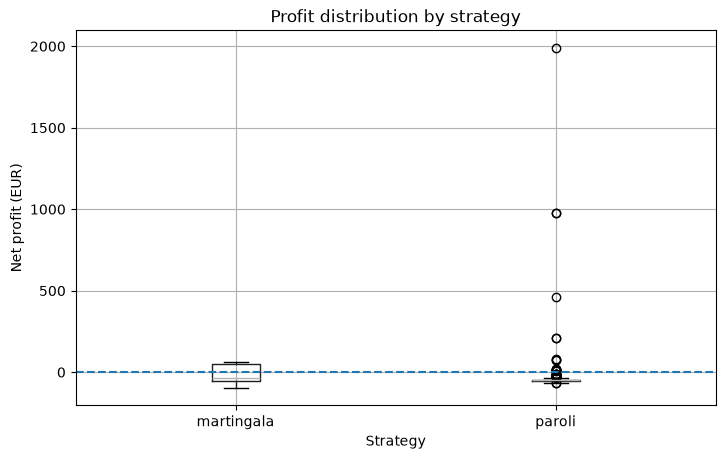

In [140]:
import matplotlib.pyplot as plt

combined_results.boxplot(
    column="net_profit",
    by="strategy",
    figsize=(8, 5)
)

plt.title("Profit distribution by strategy")
plt.suptitle("")
plt.xlabel("Strategy")
plt.ylabel("Net profit (EUR)")
plt.axhline(0, linestyle="--")
plt.show()

In [141]:
combined_results = pd.concat(
    [martingale_results, paroli_results],
    ignore_index=True
)

strategy_stats = combined_results.groupby("strategy").agg(
    sessions=("session_id", "count"),
    average_profit=("net_profit", "mean"),
    standard_deviation=("net_profit", "std"),
    minimum_profit=("net_profit", "min"),
    maximum_profit=("net_profit", "max")
)

strategy_stats

,sessions,average_profit,standard_deviation,minimum_profit,maximum_profit
strategy,,,,,
martingala,1000,-7.594,56.455189,-100,63
paroli,1000,-43.725,82.172353,-68,1992


In [142]:
paroli_results.nlargest(5, "net_profit")[
    ["session_id", "random_seed", "net_profit", "total_spins"]
]

,session_id,random_seed,net_profit,total_spins
555,paroli_batch_3p36k6er_556,655,1992,100
77,paroli_batch_3p36k6er_078,177,974,100
967,paroli_batch_3p36k6er_968,1067,974,100
372,paroli_batch_3p36k6er_373,472,461,100
874,paroli_batch_3p36k6er_875,974,211,100


In [143]:
combined_results = pd.concat(
    [martingale_results, paroli_results],
    ignore_index=True
)

combined_results["profitable"] = combined_results["net_profit"] > 0

strategy_stats = combined_results.groupby("strategy").agg(
    sessions=("session_id", "count"),
    average_profit=("net_profit", "mean"),
    median_profit=("net_profit", "median"),
    standard_deviation=("net_profit", "std"),
    minimum_profit=("net_profit", "min"),
    maximum_profit=("net_profit", "max"),
    success_rate=("profitable", "mean")
)

strategy_stats["success_rate"] *= 100

strategy_stats.round(2)

,sessions,average_profit,median_profit,standard_deviation,minimum_profit,maximum_profit,success_rate
strategy,,,,,,,
martingala,1000,-7.59,-38.0,56.46,-100,63,48.7
paroli,1000,-43.72,-50.0,82.17,-68,1992,1.6


In [150]:
import numpy as np

strategy_stats["standard_error"] = (
    strategy_stats["standard_deviation"]
    / np.sqrt(strategy_stats["sessions"])
)

In [151]:
confidence_factor = 1.96

strategy_stats["margin_of_error"] = (
    confidence_factor * strategy_stats["standard_error"]
)

strategy_stats["ci_lower"] = (
    strategy_stats["average_profit"]
    - strategy_stats["margin_of_error"]
)

strategy_stats["ci_upper"] = (
    strategy_stats["average_profit"]
    + strategy_stats["margin_of_error"]
)

strategy_stats[
    ["average_profit", "ci_lower", "ci_upper"]
].round(2)

,average_profit,ci_lower,ci_upper
strategy,,,
martingala,-7.59,-11.09,-4.09
paroli,-43.72,-48.82,-38.63


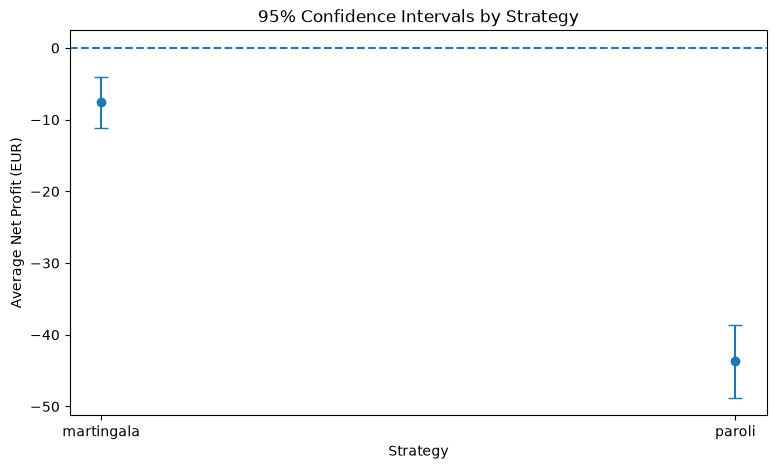

In [152]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.errorbar(
    strategy_stats.index,
    strategy_stats["average_profit"],
    yerr=strategy_stats["margin_of_error"],
    fmt="o",
    capsize=5
)

plt.axhline(0, linestyle="--")

plt.title("95% Confidence Intervals by Strategy")
plt.xlabel("Strategy")
plt.ylabel("Average Net Profit (EUR)")
plt.show()